# 01 — Data inventory

This notebook records local data availability and the metadata required before downloading SWOT, SWOT+nadir, DUACS, and GEBCO products.

The selected GESLA-4 South African tide-gauge files are staged under `data/raw/tide_gauges/`. Satellite and bathymetry data remain local, untracked inputs and are excluded from Git.

In [1]:
from pathlib import Path

REPO = Path.cwd().resolve().parent
DOWNLOAD_DIR = REPO / 'data' / 'raw'
GESLA_DIR = DOWNLOAD_DIR / 'tide_gauges'

if not GESLA_DIR.exists():
    raise FileNotFoundError(f'GESLA-4 archive not found: {GESLA_DIR}')

print(f'Repository: {REPO}')
print(f'GESLA-4 archive: {GESLA_DIR}')

Repository: <repo>
GESLA-4 archive: <repo>/data/raw/tide_gauges


In [2]:
station_names = {
    'durban': 'Durban',
    'port_elizabeth': 'Port Elizabeth',
    'richards_bay': 'Richards Bay',
    'east_london': 'East London',
    'knysna': 'Knysna',
    'mossel_bay': 'Mossel Bay',
}

metadata_keys = [
    'START DATE/TIME',
    'END DATE/TIME',
    'NUMBER OF YEARS',
    'LATITUDE',
    'LONGITUDE',
]

records = []
for stem, label in station_names.items():
    for path in sorted(GESLA_DIR.glob(f'{stem}-*zaf-*')):
        metadata = {}
        for line in path.read_text(errors='replace').splitlines():
            if not line.startswith('# '):
                continue
            content = line[2:]
            for key in metadata_keys:
                if content.startswith(key):
                    metadata[key] = content[len(key):].strip()
                    break
        records.append({
            'station': label,
            'file': path.name,
            'start': metadata.get('START DATE/TIME', 'unknown'),
            'end': metadata.get('END DATE/TIME', 'unknown'),
            'years': metadata.get('NUMBER OF YEARS', 'unknown'),
            'latitude': metadata.get('LATITUDE', 'unknown'),
            'longitude': metadata.get('LONGITUDE', 'unknown'),
        })

for record in records:
    print(record)

{'station': 'Durban', 'file': 'durban-181-zaf-uhslc_fd', 'start': '1970/09/30 22:00:00', 'end': '2026/04/30 23:00:00', 'years': '51', 'latitude': '-29.88300000', 'longitude': '31.00000000'}
{'station': 'Port Elizabeth', 'file': 'port_elizabeth-184-zaf-uhslc_fd', 'start': '1973/03/01 06:00:00', 'end': '2026/04/30 23:00:00', 'years': '49', 'latitude': '-33.96000000', 'longitude': '25.63000000'}
{'station': 'Richards Bay', 'file': 'richards_bay-188-zaf-uhslc_fd', 'start': '1977/06/08 14:00:00', 'end': '2018/10/31 23:00:00', 'years': '34', 'latitude': '-28.80000000', 'longitude': '32.08300000'}
{'station': 'East London', 'file': 'east_london-187-zaf-uhslc_fd', 'start': '1965/05/21 22:00:00', 'end': '2018/10/31 23:00:00', 'years': '46', 'latitude': '-33.00000000', 'longitude': '27.91700000'}
{'station': 'Knysna', 'file': 'knysna-186-zaf-uhslc_fd', 'start': '1966/01/01 00:00:00', 'end': '2018/10/31 23:00:00', 'years': '41', 'latitude': '-34.08300000', 'longitude': '23.05000000'}
{'station': 

In [3]:
# Load and inspect all GESLA station records.
import pandas as pd
import plotly.express as px

station_names = {
    'durban': 'Durban',
    'port_elizabeth': 'Port Elizabeth',
    'richards_bay': 'Richards Bay',
    'east_london': 'East London',
    'knysna': 'Knysna',
    'mossel_bay': 'Mossel Bay',
}

records = []
for stem, label in station_names.items():
    path = next(GESLA_DIR.glob(f'{stem}-*zaf-*'), None)
    if path is None:
        print(f'Missing station file for {label}: {stem}')
        continue

    df = pd.read_csv(
        path,
        sep=r'\s+',
        comment='#',
        header=None,
        names=['date', 'time', 'sea_level_m', 'qc_flag', 'use_flag'],
        na_values=['-99.9999'],
    )
    df['station'] = label
    df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])
    df = df[['station', 'datetime', 'sea_level_m', 'qc_flag', 'use_flag']]
    records.append(df)

all_gauges = pd.concat(records, ignore_index=True)
all_gauges = all_gauges[all_gauges['use_flag'] == 1].copy()
all_gauges = all_gauges.sort_values(['station', 'datetime']).reset_index(drop=True)

print(f'Loaded {len(all_gauges):,} valid hourly samples across {all_gauges["station"].nunique()} stations.')
print(all_gauges.groupby('station').agg(
    start=('datetime', 'min'),
    end=('datetime', 'max'),
    n=('sea_level_m', 'size'),
).reset_index())

# SWOT science-orbit phase start (per docs/data_inventory.md: working period begins July 2023,
# after the Cal/Val phase). SWOT_END=None keeps the window open to the latest gauge sample.
SWOT_START = pd.Timestamp('2023-07-01')
SWOT_END = None

swot_window_end = all_gauges['datetime'].max() if SWOT_END is None else pd.Timestamp(SWOT_END)
swot_gauges = all_gauges[
    (all_gauges['datetime'] >= SWOT_START) & (all_gauges['datetime'] <= swot_window_end)
].copy()

print(f'\nSWOT flying window: {SWOT_START.date()} to {swot_window_end.date()}')
print(f'{len(swot_gauges):,} valid samples in the SWOT window across {swot_gauges["station"].nunique()} stations.')
print(swot_gauges.groupby('station').agg(
    start=('datetime', 'min'),
    end=('datetime', 'max'),
    n=('sea_level_m', 'size'),
).reset_index())

fig = px.line(
    swot_gauges,
    x='datetime',
    y='sea_level_m',
    color='station',
    title=f'GESLA South African tide-gauge sea level records during SWOT operations ({SWOT_START.date()} onward)',
    labels={'datetime': 'Time', 'sea_level_m': 'Observed sea level (m)', 'station': 'Station'},
    category_orders={'station': list(station_names.values())},
    template='plotly_white',
    hover_data={'station': True, 'datetime': '|%Y-%m-%d %H:%M', 'sea_level_m': ':.4f'},
)
fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(
    height=650,
    legend=dict(
        orientation='h', yanchor='bottom', y=1.02, xanchor='left', x=0,
        itemclick='toggle', itemdoubleclick='toggleothers',
    ),
)
fig.show()
print('Click a station in the legend to toggle it off/on; double-click a station to isolate it.')


Loaded 1,864,885 valid hourly samples across 6 stations.
          station               start                 end       n
0          Durban 1970-09-30 22:00:00 2026-04-30 23:00:00  336922
1     East London 1965-05-21 22:00:00 2018-10-31 23:00:00  278743
2          Knysna 1966-01-01 00:00:00 2018-10-31 23:00:00  311222
3      Mossel Bay 1964-01-01 00:00:00 2018-10-31 23:00:00  363179
4  Port Elizabeth 1973-03-01 06:00:00 2026-04-30 23:00:00  361323
5    Richards Bay 1977-06-08 14:00:00 2018-10-31 23:00:00  213496

SWOT flying window: 2023-07-01 to 2026-04-30
45,287 valid samples in the SWOT window across 2 stations.
          station      start                 end      n
0          Durban 2023-07-01 2026-04-30 23:00:00  21209
1  Port Elizabeth 2023-07-01 2026-04-30 23:00:00  24078


Click a station in the legend to toggle it off/on; double-click a station to isolate it.


## Load and visualise HF radar surface currents

The local HF-radar archive contains 30-minute NetCDF files with eastward (`ewct`) and northward (`nsct`) surface-current components on a 6 km grid. The loader combines the dated files lazily, excludes duplicate files with a `(1)` suffix, and derives current speed for interactive viewing.

In [4]:
# Load one readable HF-radar file and define the approximate radar study domain.
import numpy as np
import pandas as pd
import xarray as xr

HF_RADAR_DIR = REPO / 'data' / 'raw' / 'hf_radar'
HF_RADAR_CANDIDATES = sorted(
    path for path in HF_RADAR_DIR.glob('*/*/radar_sa_*_combined_hyddoa.nc')
    if '(1)' not in path.name
)

if not HF_RADAR_CANDIDATES:
    raise FileNotFoundError(f'No HF-radar NetCDF files found under {HF_RADAR_DIR}')

HF_RADAR_FILE = None
HF_RADAR_SKIPPED = []
for path in HF_RADAR_CANDIDATES:
    try:
        with xr.open_dataset(path, engine='netcdf4'):
            pass
        HF_RADAR_FILE = path
        break
    except (OSError, ValueError, RuntimeError) as error:
        HF_RADAR_SKIPPED.append((path, f'{type(error).__name__}: {error}'))

if HF_RADAR_FILE is None:
    raise OSError('No readable HF-radar NetCDF file found.')

HF_RADAR_SAMPLE = xr.open_dataset(HF_RADAR_FILE, engine='netcdf4')
HF_RADAR_SAMPLE['speed'] = np.hypot(HF_RADAR_SAMPLE['ewct'], HF_RADAR_SAMPLE['nsct'])

# Approximate HF-radar study domain: 21-26 E, 34-37 S.
HF_RADAR_BBOX = (21.0, 26.0, -37.0, -34.0)

print(f'HF-radar sample: {HF_RADAR_FILE.name}')
print(f'Sample time: {pd.Timestamp(HF_RADAR_SAMPLE.time.values[0])}')
print(f'Approximate radar bounding box: {HF_RADAR_BBOX}')
print(f'Grid: {HF_RADAR_SAMPLE.sizes["latitude"]} latitude x {HF_RADAR_SAMPLE.sizes["longitude"]} longitude')
print(f'Skipped unreadable files before sample: {len(HF_RADAR_SKIPPED)}')

HF-radar sample: radar_sa_202411101530_combined_hyddoa.nc
Sample time: 2024-11-10 15:30:00
Approximate radar bounding box: (21.0, 26.0, -37.0, -34.0)
Grid: 75 latitude x 150 longitude
Skipped unreadable files before sample: 0


In [5]:
# Interactive viewer for HF-radar surface current snapshots.
import re
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import clear_output, display

RADAR_VECTOR_STRIDE = 2
RADAR_PLOT_MARGIN = 0.25
RADAR_QUIVER_SCALE = 40

# Build timestamped inventory of all readable HF-radar candidate files
radar_records = []
for file_path in HF_RADAR_CANDIDATES:
    time_match = re.search(r'radar_sa_(\d{12})_combined', file_path.name)
    if time_match:
        ts = pd.to_datetime(time_match.group(1), format='%Y%m%d%H%M')
        radar_records.append({
            'path': file_path,
            'datetime': ts,
            'label': f'{ts:%Y-%m-%d %H:%M} UTC ({file_path.name})',
        })

radar_records.sort(key=lambda r: r['datetime'])
if not radar_records:
    raise FileNotFoundError('No timestamped HF-radar NetCDF files found.')

# Compute fixed geographic extent from the sample dataset
sample_frame = HF_RADAR_SAMPLE.isel(time=0) if 'time' in HF_RADAR_SAMPLE.dims else HF_RADAR_SAMPLE
sample_speed = sample_frame['speed'].values
valid_sample_grid = np.isfinite(sample_speed)
valid_lat, valid_lon = np.meshgrid(
    sample_frame.latitude.values,
    sample_frame.longitude.values,
    indexing='ij',
)
plot_longitudes = valid_lon[valid_sample_grid]
plot_latitudes = valid_lat[valid_sample_grid]
plot_bounds = (
    plot_longitudes.min() - RADAR_PLOT_MARGIN,
    plot_longitudes.max() + RADAR_PLOT_MARGIN,
    plot_latitudes.min() - RADAR_PLOT_MARGIN,
    plot_latitudes.max() + RADAR_PLOT_MARGIN,
)


def plot_radar_snapshot(record):
    with xr.open_dataset(record['path'], engine='netcdf4') as dataset:
        frame = dataset.isel(time=0) if 'time' in dataset.dims else dataset
        speed = np.hypot(frame['ewct'], frame['nsct'])
        lon_sub = frame.longitude.values[::RADAR_VECTOR_STRIDE]
        lat_sub = frame.latitude.values[::RADAR_VECTOR_STRIDE]
        u_sub = frame['ewct'].values[::RADAR_VECTOR_STRIDE, ::RADAR_VECTOR_STRIDE]
        v_sub = frame['nsct'].values[::RADAR_VECTOR_STRIDE, ::RADAR_VECTOR_STRIDE]
        valid_vec = np.isfinite(u_sub) & np.isfinite(v_sub)
        u_sub = np.where(valid_vec, u_sub, np.nan)
        v_sub = np.where(valid_vec, v_sub, np.nan)
        lon_grid, lat_grid = np.meshgrid(lon_sub, lat_sub)
        speed_vals = speed.values

    vmax_val = float(np.nanpercentile(speed_vals, 98)) if np.isfinite(speed_vals).any() else 1.0
    if not np.isfinite(vmax_val) or vmax_val <= 0:
        vmax_val = 1.0

    figure, axis = plt.subplots(figsize=(10, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    axis.set_extent(plot_bounds, crs=ccrs.PlateCarree())
    axis.add_feature(cfeature.LAND, facecolor='#e7e2d8', edgecolor='black', linewidth=0.8, zorder=4)
    axis.coastlines(resolution='10m', color='black', linewidth=1.2, zorder=5)

    speed.plot.pcolormesh(
        ax=axis,
        x='longitude',
        y='latitude',
        cmap='viridis',
        vmin=0,
        vmax=vmax_val,
        cbar_kwargs={'label': 'Current speed (m s$^{-1}$)'},
        transform=ccrs.PlateCarree(),
        zorder=1,
    )
    axis.quiver(
        lon_grid,
        lat_grid,
        u_sub,
        v_sub,
        color='white',
        scale=RADAR_QUIVER_SCALE,
        width=0.0015,
        headwidth=5,
        headlength=3,
        headaxislength=3.5,
        pivot='mid',
        transform=ccrs.PlateCarree(),
        zorder=6,
    )
    axis.plot(25.63, -33.96, marker='*', color='darkgreen', markersize=10, transform=ccrs.PlateCarree(), zorder=7)
    axis.annotate('Port Elizabeth', (25.63, -33.96), xytext=(5, 5), textcoords='offset points', color='darkgreen', zorder=7)
    axis.set_title(f"HF radar surface currents: {record['datetime']:%Y-%m-%d %H:%M} UTC")
    axis.set_xlabel('Longitude (degrees east)')
    axis.set_ylabel('Latitude (degrees south)')
    axis.gridlines(draw_labels=True, linewidth=0.5, color='white', alpha=0.5)
    figure.tight_layout()
    plt.show()


radar_selector = widgets.Dropdown(
    options=[(r['label'], i) for i, r in enumerate(radar_records)],
    value=0,
    description='Timestamp:',
    layout=widgets.Layout(width='500px'),
)
radar_prev_btn = widgets.Button(description='Previous', icon='arrow-left')
radar_next_btn = widgets.Button(description='Next', icon='arrow-right')
radar_plot_output = widgets.Output()


def show_selected_radar(index):
    radar_selector.value = index % len(radar_records)
    selected_record = radar_records[radar_selector.value]
    with radar_plot_output:
        clear_output(wait=True)
        plot_radar_snapshot(selected_record)


radar_prev_btn.on_click(lambda _: show_selected_radar(radar_selector.value - 1))
radar_next_btn.on_click(lambda _: show_selected_radar(radar_selector.value + 1))
radar_selector.observe(lambda change: show_selected_radar(change['new']) if change['name'] == 'value' else None)

display(
    widgets.VBox([
        widgets.HBox([radar_prev_btn, radar_next_btn, radar_selector]),
        radar_plot_output,
    ])
)
show_selected_radar(0)

HDF5-DIAG: Error detected in HDF5 (2.1.0) thread 2:
  #000: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5F.c line 821 in H5Fopen(): unable to synchronously open file
    major: File accessibility
    minor: Unable to open file
  #001: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5F.c line 782 in H5F__open_api_common(): unable to open file
    major: File accessibility
    minor: Unable to open file
  #002: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLcallback.c line 3869 in H5VL_file_open(): open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLcallback.c line 3718 in H5VL__file_open(): open failed
    major: Virtual Object Layer
    minor: Can't open object
  #004: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLnative_file.c line 128 in H5VL__native_file_open(): unable to open file
    major: File accessibility
 

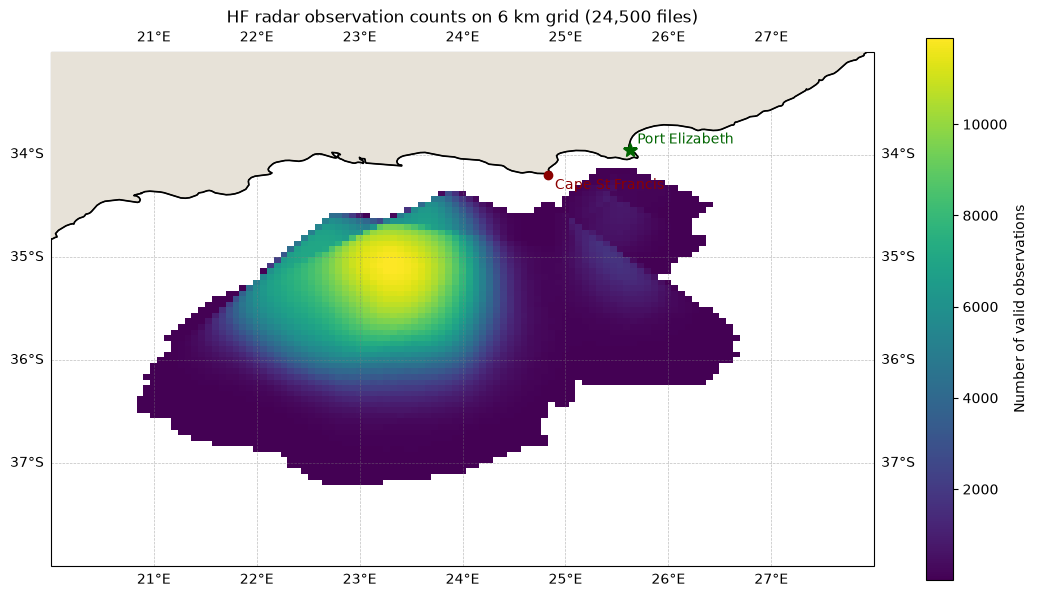

Total HF-radar candidate files: 24,500
Maximum observations in a single grid cell: 11,900
Grid cells with at least 1 observation: 3,143
Plot extent (lon_min, lon_max, lat_min, lat_max): (20.0, 28.0, -38.0, -33.0)


In [6]:
# Map spatial distribution of total HF-radar observation counts on the 6 km grid.
from concurrent.futures import ThreadPoolExecutor
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import netCDF4
import numpy as np

# Use the 6 km grid coordinates from the HF radar dataset
radar_grid_lat = sample_frame.latitude.values
radar_grid_lon = sample_frame.longitude.values
grid_shape = (len(radar_grid_lat), len(radar_grid_lon))


def accumulate_chunk(file_paths):
    count_chunk = np.zeros(grid_shape, dtype=np.int32)
    for path in file_paths:
        try:
            with netCDF4.Dataset(path, 'r') as dataset:
                u_var = dataset.variables['ewct'][0]
                if hasattr(u_var, 'mask'):
                    count_chunk += (~u_var.mask).astype(np.int32)
                else:
                    count_chunk += np.isfinite(u_var).astype(np.int32)
        except Exception:
            continue
    return count_chunk


# Accumulate valid observations across all candidate HF-radar files
num_workers = 16
chunk_size = int(np.ceil(len(HF_RADAR_CANDIDATES) / num_workers))
file_chunks = [
    HF_RADAR_CANDIDATES[i:i + chunk_size]
    for i in range(0, len(HF_RADAR_CANDIDATES), chunk_size)
]

with ThreadPoolExecutor(max_workers=num_workers) as executor:
    results = list(executor.map(accumulate_chunk, file_chunks))

hf_radar_obs_count = sum(results)

# Domain bounds: 20E-28E, 38S-33S (lon_min, lon_max, lat_min, lat_max)
plot_bounds_extended = (20.0, 28.0, -38.0, -33.0)

# Plot observation count map on the 6 km grid
figure, axis = plt.subplots(figsize=(11, 6), subplot_kw={'projection': ccrs.PlateCarree()})
axis.set_extent(plot_bounds_extended, crs=ccrs.PlateCarree())
axis.add_feature(cfeature.LAND, facecolor='#e7e2d8', edgecolor='black', linewidth=0.8, zorder=4)
axis.coastlines(resolution='10m', color='black', linewidth=1.2, zorder=5)

count_display = np.where(hf_radar_obs_count > 0, hf_radar_obs_count, np.nan)
mesh = axis.pcolormesh(
    radar_grid_lon,
    radar_grid_lat,
    count_display,
    cmap='viridis',
    shading='nearest',
    transform=ccrs.PlateCarree(),
    zorder=1,
)
figure.colorbar(mesh, ax=axis, label='Number of valid observations')

axis.plot(25.63, -33.96, marker='*', color='darkgreen', markersize=10, transform=ccrs.PlateCarree(), zorder=6)
axis.annotate('Port Elizabeth', (25.63, -33.96), xytext=(5, 5), textcoords='offset points', color='darkgreen', zorder=6)
axis.plot(24.83, -34.20, marker='o', color='darkred', markersize=6, transform=ccrs.PlateCarree(), zorder=6)
axis.annotate('Cape St Francis', (24.83, -34.20), xytext=(5, -10), textcoords='offset points', color='darkred', zorder=6)

axis.set_title(f'HF radar observation counts on 6 km grid ({len(HF_RADAR_CANDIDATES):,} files)')
axis.set_xlabel('Longitude (degrees east)')
axis.set_ylabel('Latitude (degrees south)')
axis.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
figure.tight_layout()
plt.show()

print(f'Total HF-radar candidate files: {len(HF_RADAR_CANDIDATES):,}')
print(f'Maximum observations in a single grid cell: {hf_radar_obs_count.max():,}')
print(f'Grid cells with at least 1 observation: {(hf_radar_obs_count > 0).sum():,}')
print(f'Plot extent (lon_min, lon_max, lat_min, lat_max): {plot_bounds_extended}')

## Select and download SWOT L3 LR SSH Expert overpasses

The AVISO handbook documents v3.0 L3 Expert coverage from 26 July 2023 onward. The downloader therefore walks the complete v3.0 Expert catalogue, including reprocessed and forward branches, and selects covering pass numbers within the requested date range.

This downloads L3 Expert data for the established tide-gauge and HF-radar pass targets. It does not download the separate 250 m Unsmoothed product.

In [7]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import altimetry_downloader_aviso as dl_aviso

DOWNLOAD_DIR = REPO / 'data' / 'raw'
SWOT_L3_DIR = DOWNLOAD_DIR / 'swot_l3_expert'
SWOT_L3_DIR.mkdir(parents=True, exist_ok=True)

# Single explicit domain bounding box: 22-32 E, 28-38 S.
DOMAIN_BBOX = (22.0, 32.0, -38.0, -28.0)
TARGET_POINTS = {
    'Durban': (31.000, -29.883),
    'Port Elizabeth': (25.630, -33.960),
    'Richards Bay': (32.083, -28.800),
    'East London': (27.917, -33.000),
    'Knysna': (23.050, -34.083),
    'Mossel Bay': (22.133, -34.183),
}

# Existing local files provide seed pass geometries for the target region.
SEED_L3_FILES = sorted(SWOT_L3_DIR.glob('SWOT_L3_LR_SSH_Expert_*.nc'))
if not SEED_L3_FILES:
    raise FileNotFoundError('No local L3 Expert files available to identify covering passes.')

LON_MIN, LON_MAX = DOMAIN_BBOX[0], DOMAIN_BBOX[1]
LAT_MIN, LAT_MAX = DOMAIN_BBOX[2], DOMAIN_BBOX[3]
SWOT_START_DATE = pd.Timestamp('2023-07-26')
SWOT_END_DATE = pd.Timestamp('2026-09-11')
DOWNLOAD = True
PLOT_FILE_INDEX = 0

print(f'L3 Expert directory: {SWOT_L3_DIR}')
print(f'Domain bounding box (lon_min, lon_max, lat_min, lat_max): {DOMAIN_BBOX}')
print(f'Seed files for pass selection: {len(SEED_L3_FILES)}')
print(f'Date range: {SWOT_START_DATE.date()} to {SWOT_END_DATE.date()}')
print('Download mode: all v3.0 Expert branches and cycles for covering pass numbers')

L3 Expert directory: <repo>/data/raw/swot_l3_expert
Domain bounding box (lon_min, lon_max, lat_min, lat_max): (22.0, 32.0, -38.0, -28.0)
Seed files for pass selection: 688
Date range: 2023-07-26 to 2026-09-11
Download mode: all v3.0 Expert branches and cycles for covering pass numbers


### AVISO+ authentication

Protected AVISO products require credentials. The downloader stores them in `~/.altimetry/.netrc` and configures the environment used by `requests` and `netCDF4`; credentials are never written to the notebook.

In [8]:
from altimetry_downloader_aviso.auth import NETRC_PATH, ensure_credentials

# This prompts once if credentials are not already configured.
ensure_credentials('tds-odatis.aviso.altimetry.fr')
print(f'AVISO+ credentials configured through {NETRC_PATH}')

AVISO+ credentials configured through ~/.altimetry/.netrc


<env>/lib/python3.11/site-packages/altimetry_downloader_aviso/auth.py:87: UserWarning: netCDF4 is already loaded. Authentication configuration may not be applied
  warnings.warn(msg)


In [9]:
# Catalogue discovery for the one product used in this notebook:
# SWOT L3 LR SSH Expert, version 3.0.
import requests
import xml.etree.ElementTree as ET

PRODUCT_SHORT_NAME = 'SWOT_L3_LR_SSH_Expert'
TDS_L3_CATALOG = (
    'https://tds-odatis.aviso.altimetry.fr/thredds/catalog/'
    'dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/catalog.xml'
)

try:
    aviso_catalogue = dl_aviso.summary()
    matching_products = [
        product for product in aviso_catalogue.products
        if product.short_name == PRODUCT_SHORT_NAME
    ]
    print('Selected product:')
    for product in matching_products:
        print(f'  {product.short_name} -> {product.title}')
    if not matching_products:
        print(f'Product not found in GeoNetwork catalogue: {PRODUCT_SHORT_NAME}')
except Exception as error:
    print(f'GeoNetwork catalogue unavailable: {error}')

try:
    response = requests.get(TDS_L3_CATALOG, timeout=30)
    response.raise_for_status()
    root = ET.fromstring(response.content)
    namespace = {'thredds': 'http://www.unidata.ucar.edu/namespaces/thredds/InvCatalog/v1.0'}
    references = root.findall('.//thredds:catalogRef', namespace)
    versions = [
        ref.attrib.get('{http://www.w3.org/1999/xlink}title')
        for ref in references
    ]
    print(f'\nL3 Expert catalogue: {TDS_L3_CATALOG}')
    print(f'Available versions: {versions}')
    print('Selected version: v3_0')
except (requests.RequestException, ET.ParseError) as error:
    print(f'L3 Expert catalogue unavailable: {type(error).__name__}: {error}')

Selected product:
  SWOT_L3_LR_SSH_Expert -> Altimetry product SWOT Level-3 Low Rate SSH - Expert

L3 Expert catalogue: https://tds-odatis.aviso.altimetry.fr/thredds/catalog/dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/catalog.xml
Available versions: ['v2_0_1', 'v3_0']
Selected version: v3_0


In [10]:
# Discover catalogue granules and download only the requested SWOT L3 Expert passes.
from concurrent.futures import ThreadPoolExecutor, as_completed
from netrc import netrc
from urllib.parse import urljoin
import time
import requests
import xml.etree.ElementTree as ET

DOWNLOAD_HOST = 'tds-odatis.aviso.altimetry.fr'
credentials = netrc(NETRC_PATH).authenticators(DOWNLOAD_HOST)
if credentials is None:
    raise RuntimeError(f'No AVISO+ credentials found for {DOWNLOAD_HOST} in {NETRC_PATH}')
TDS_AUTH = (credentials[0], credentials[2])

TDS_ROOT = 'https://tds-odatis.aviso.altimetry.fr/thredds'
TDS_VERSION_ROOT = f'{TDS_ROOT}/catalog/dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/v3_0/Expert'
TDS_PARENT_CATALOG = f'{TDS_VERSION_ROOT}/catalog.xml'
TDS_FILESERVER_ROOT = f'{TDS_ROOT}/fileServer'
XML_NAMESPACE = {'thredds': 'http://www.unidata.ucar.edu/namespaces/thredds/InvCatalog/v1.0'}
XLINK_HREF = '{http://www.w3.org/1999/xlink}href'

# Explicitly requested passes. No spatial verification or probe downloads are run.
COVERING_PASS_NUMBERS = [
    430, 443, 458, 471, 486, 499,
    514, 527, 542, 555, 570, 583,
]
MAX_WORKERS = 8
DOWNLOAD_WORKERS = 4


def read_catalog(catalog_url):
    response = requests.get(catalog_url, auth=TDS_AUTH, timeout=30)
    response.raise_for_status()
    return ET.fromstring(response.content)


def download_granule(url_path, local_file, max_retries=3, backoff_seconds=5):
    http_url = f'{TDS_FILESERVER_ROOT}/{url_path}'
    for attempt in range(1, max_retries + 1):
        try:
            response_download = requests.get(http_url, auth=TDS_AUTH, timeout=120, stream=True)
            response_download.raise_for_status()
            with open(local_file, 'wb') as output_file:
                for chunk in response_download.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output_file.write(chunk)
            return
        except (requests.exceptions.RequestException, OSError) as error:
            local_file.unlink(missing_ok=True)
            if attempt == max_retries:
                raise
            print(f'    Retry {attempt}/{max_retries} after {type(error).__name__}: {error}')
            time.sleep(backoff_seconds * attempt)


# Walk the parent catalogue so reprocessed and forward branches are both included.
pending_catalogs = [TDS_PARENT_CATALOG]
visited_catalogs = set()
cycle_catalogs = {}
while pending_catalogs:
    catalog_url = pending_catalogs.pop()
    if catalog_url in visited_catalogs:
        continue
    visited_catalogs.add(catalog_url)
    try:
        root = read_catalog(catalog_url)
    except (requests.RequestException, ET.ParseError) as error:
        print(f'Catalogue unavailable: {catalog_url} ({type(error).__name__})')
        continue

    for reference in root.findall('.//thredds:catalogRef', XML_NAMESPACE):
        child_catalog = urljoin(catalog_url, reference.attrib.get(XLINK_HREF, ''))
        cycle_match = re.search(r'/cycle_(\d+)/catalog\.xml$', child_catalog)
        if cycle_match:
            cycle_catalogs[child_catalog] = int(cycle_match.group(1))
        elif child_catalog.endswith('.xml'):
            pending_catalogs.append(child_catalog)

print(f'Catalogue branches visited: {len(visited_catalogs)}')
print(f'Cycle catalogues discovered: {len(cycle_catalogs)}')


# Fetch each cycle listing once and reuse it to build the download manifest.
def fetch_cycle_granules(cycle_catalog):
    try:
        root = read_catalog(cycle_catalog)
        return cycle_catalog, [
            (dataset.attrib['name'], dataset.attrib.get('urlPath'))
            for dataset in root.findall('.//thredds:dataset[@name]', XML_NAMESPACE)
        ]
    except (requests.RequestException, ET.ParseError) as error:
        print(f'Cycle {cycle_catalogs[cycle_catalog]}: catalogue unavailable ({type(error).__name__})')
        return cycle_catalog, []


cycle_granules = {}
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(fetch_cycle_granules, catalog) for catalog in cycle_catalogs]
    for future in as_completed(futures):
        catalog, granules = future.result()
        cycle_granules[catalog] = granules

print(f'Requested pass numbers: {COVERING_PASS_NUMBERS}')

# Build a date-filtered, de-duplicated manifest before starting downloads.
download_manifest = []
manifest_paths = set()
for cycle_catalog, cycle in sorted(cycle_catalogs.items(), key=lambda item: (item[1], item[0])):
    for granule_name, url_path in cycle_granules.get(cycle_catalog, []):
        pass_match = re.search(r'_(\d{3})_(\d{3})_', granule_name)
        date_match = re.search(r'_(\d{8})T\d{6}_', granule_name)
        if pass_match is None or date_match is None or not url_path:
            continue
        if int(pass_match.group(2)) not in COVERING_PASS_NUMBERS:
            continue
        granule_date = pd.Timestamp(date_match.group(1))
        if not (SWOT_START_DATE <= granule_date <= SWOT_END_DATE):
            continue
        local_file = SWOT_L3_DIR / granule_name
        if local_file in manifest_paths:
            continue
        manifest_paths.add(local_file)
        download_manifest.append((granule_name, url_path, local_file))

L3_TEST_FILES = []
FAILED_DOWNLOADS = []
NOT_DOWNLOADED = []
pending_downloads = []
for granule_name, url_path, local_file in download_manifest:
    if local_file.exists():
        L3_TEST_FILES.append(str(local_file))
    elif DOWNLOAD:
        pending_downloads.append((granule_name, url_path, local_file))
    else:
        NOT_DOWNLOADED.append(granule_name)

print(f'Download manifest: {len(download_manifest)} files')
print(f'Already present: {len(L3_TEST_FILES)}')
print(f'Remaining to download: {len(pending_downloads)}')


def download_one(entry):
    granule_name, url_path, local_file = entry
    try:
        download_granule(url_path, local_file)
        return granule_name, local_file, None
    except Exception as error:
        return granule_name, local_file, f'{type(error).__name__}: {error}'


if pending_downloads:
    completed_count = len(L3_TEST_FILES)
    started_at = time.monotonic()
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as executor:
        futures = [executor.submit(download_one, entry) for entry in pending_downloads]
        for future in as_completed(futures):
            granule_name, local_file, error = future.result()
            completed_count += 1
            if error is None and local_file.exists():
                L3_TEST_FILES.append(str(local_file))
                status = 'complete'
            else:
                FAILED_DOWNLOADS.append(granule_name)
                status = f'failed ({error})'
            elapsed_minutes = (time.monotonic() - started_at) / 60
            print(f'Download progress: {completed_count}/{len(download_manifest)} '
                  f'({100 * completed_count / len(download_manifest):.1f}%) - '
                  f'{status}: {granule_name} - {elapsed_minutes:.1f} min elapsed')
else:
    print('No new downloads required.')

print(f'\nSelected local files: {len(L3_TEST_FILES)}')
if FAILED_DOWNLOADS:
    print(f'Failed downloads (re-run this cell to retry): {len(FAILED_DOWNLOADS)}')
    for name in FAILED_DOWNLOADS:
        print(f'  {name}')
if NOT_DOWNLOADED:
    print(f'Download disabled for {len(NOT_DOWNLOADED)} missing files.')

Catalogue branches visited: 3
Cycle catalogues discovered: 160
Requested pass numbers: [430, 443, 458, 471, 486, 499, 514, 527, 542, 555, 570, 583]
Download manifest: 653 files
Already present: 653
Remaining to download: 0
No new downloads required.

Selected local files: 653


In [11]:
# # Inspect selected L3 Expert v3.0 files and report target coverage.
# import xarray as xr


# def coverage_flags(file_path):
#     with xr.open_dataset(file_path) as dataset:
#         longitude = dataset.longitude
#         latitude = dataset.latitude
#         valid = dataset['ssha_filtered'].notnull()
#         flags = {}

#         for name, (target_lon, target_lat) in TARGET_POINTS.items():
#             flags[name] = bool(
#                 (valid &
#                  (abs(longitude - target_lon) <= 0.25) &
#                  (abs(latitude - target_lat) <= 0.25)).any().item()
#             )

#         if HF_RADAR_BBOX is None:
#             flags['HF radar'] = 'bbox not set'
#         else:
#             min_lon, max_lon, min_lat, max_lat = HF_RADAR_BBOX
#             flags['HF radar'] = bool(
#                 (valid &
#                  (longitude >= min_lon) & (longitude <= max_lon) &
#                  (latitude >= min_lat) & (latitude <= max_lat)).any().item()
#             )

#         return dataset, flags


# for file_path in L3_TEST_FILES:
#     dataset, flags = coverage_flags(file_path)
#     print(f'\nL3 Expert: {Path(file_path).name}')
#     print('Dimensions:', dict(dataset.sizes))
#     print('Coverage:', flags)
#     print('SSH variables:', [name for name in dataset.data_vars if 'ssh' in name.lower()])
#     dataset.close()

In [12]:
# Interactive viewer for selected SWOT L3 Expert passes and matched HF-radar footprints.
import re
import warnings
from datetime import datetime, timedelta
import geopandas as gpd
from IPython.display import clear_output, display
import ipywidgets as widgets
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from shapely.geometry import box
import xarray as xr

if not L3_TEST_FILES:
    raise ValueError('No L3 files selected. Run the download cell first.')

# Filter specifically to requested passes: 486, 499, 514, 527, 542, 555
REQUESTED_PASSES = {486, 499, 514, 527, 542, 555}

# Domain bounds: 20E-28E and 33S-38S (lon_min, lon_max, lat_min, lat_max)
SWOT_PLOT_BOUNDS = (20.0, 28.0, -38.0, -33.0)

# Fixed colour scale so the SSH anomaly range is consistent across passes.
SWOT_COLOR_LIMIT = 0.5


def parse_pass_metadata(file_path):
    name = Path(file_path).name
    pass_match = re.search(r'_(\d{3})_(\d{3})_', name)
    date_match = re.search(r'_(\d{8}T\d{6})_', name)
    if pass_match is None or date_match is None:
        raise ValueError(f'Could not parse cycle, pass, and date from {name}')
    pass_datetime = datetime.strptime(date_match.group(1), '%Y%m%dT%H%M%S')
    return {
        'path': file_path,
        'cycle': int(pass_match.group(1)),
        'pass': int(pass_match.group(2)),
        'datetime': pass_datetime,
        'date': pass_datetime.date().isoformat(),
        'label': f'{pass_datetime:%Y-%m-%d %H:%M} | cycle {pass_match.group(1)} | pass {pass_match.group(2)}',
    }


def pass_intersects_domain(file_path, bounds):
    lon_min, lon_max, lat_min, lat_max = bounds
    with xr.open_dataset(file_path) as dataset:
        valid = dataset['ssha_filtered'].notnull()
        longitude = dataset.longitude
        latitude = dataset.latitude
        return bool((
            valid
            & (longitude >= lon_min) & (longitude <= lon_max)
            & (latitude >= lat_min) & (latitude <= lat_max)
        ).any().item())


# Index available HF-radar candidate files by timestamp
radar_file_timestamps = []
for rf in HF_RADAR_CANDIDATES:
    tm = re.search(r'radar_sa_(\d{12})_combined', rf.name)
    if tm:
        radar_file_timestamps.append((datetime.strptime(tm.group(1), '%Y%m%d%H%M'), rf))
radar_file_timestamps.sort(key=lambda item: item[0])

# Filter and sort SWOT passes
matching_files = [
    file_path for file_path in L3_TEST_FILES
    if any(f'_{p:03d}_' in Path(file_path).name for p in REQUESTED_PASSES)
    and pass_intersects_domain(file_path, SWOT_PLOT_BOUNDS)
]
if not matching_files:
    raise ValueError('No downloaded L3 files match the requested passes and map domain.')

pass_records = sorted(
    (parse_pass_metadata(file_path) for file_path in matching_files),
    key=lambda record: (record['datetime'], record['cycle'], record['pass']),
)
print(f'Matching overpasses in domain: {len(pass_records)}')

BASEMAP_FILE = DOWNLOAD_DIR / 'basemaps' / 'ne_10m_land.zip'
if not BASEMAP_FILE.exists():
    BASEMAP_FILE.parent.mkdir(parents=True, exist_ok=True)
    response = requests.get(
        'https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip',
        timeout=60,
    )
    response.raise_for_status()
    BASEMAP_FILE.write_bytes(response.content)

land = gpd.read_file(BASEMAP_FILE).clip(
    box(SWOT_PLOT_BOUNDS[0], SWOT_PLOT_BOUNDS[2], SWOT_PLOT_BOUNDS[1], SWOT_PLOT_BOUNDS[3])
)


def get_nearest_radar_footprint(swot_dt):
    if not radar_file_timestamps:
        return None, None, None
    best_diff, best_radar_dt, best_radar_file = min(
        [(abs(rt - swot_dt), rt, rf) for rt, rf in radar_file_timestamps],
        key=lambda x: x[0],
    )
    if best_diff > timedelta(hours=3):
        return None, best_radar_dt, best_diff
    with xr.open_dataset(best_radar_file, engine='netcdf4') as rds:
        rframe = rds.isel(time=0) if 'time' in rds.dims else rds
        rspeed = np.hypot(rframe['ewct'], rframe['nsct']).values
        rlon_grid, rlat_grid = np.meshgrid(rframe.longitude.values, rframe.latitude.values)
        rfootprint = np.isfinite(rspeed).astype(float)
    return (rlon_grid, rlat_grid, rfootprint), best_radar_dt, best_diff


def records_in_window(selected_record, window_days):
    selected_date = selected_record['datetime'].date()
    window_start = selected_date - timedelta(days=(window_days - 1) // 2)
    window_end = window_start + timedelta(days=window_days - 1)
    return [
        record for record in pass_records
        if window_start <= record['datetime'].date() <= window_end
    ]


def plot_passes(records, selected_record, window_days):
    figure, axis = plt.subplots(figsize=(10, 6))
    land.plot(ax=axis, color='#e7e2d8', zorder=2)
    land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
    mesh = None

    for record in records:
        with xr.open_dataset(record['path']) as dataset:
            valid = dataset['ssha_filtered'].notnull()
            l3_ssha = dataset['ssha_filtered'].where(valid).load()
            longitude = dataset.longitude.values
            latitude = dataset.latitude.values

        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='.*input coordinates to pcolormesh.*')
            mesh = axis.pcolormesh(
                longitude,
                latitude,
                l3_ssha.values,
                cmap='RdBu_r',
                vmin=-SWOT_COLOR_LIMIT,
                vmax=SWOT_COLOR_LIMIT,
                shading='nearest',
                zorder=1,
            )

    if mesh is None:
        raise ValueError('No SWOT passes are available in the selected date window.')

    figure.colorbar(mesh, ax=axis, label='Sea surface height anomaly (m)')

    # Find and overlay matching HF-radar footprint for the centre pass
    radar_grid_data, radar_dt, radar_gap = get_nearest_radar_footprint(selected_record['datetime'])
    legend_handles = []
    if radar_grid_data is not None:
        rlon, rlat, rmask = radar_grid_data
        if np.any(rmask > 0):
            axis.contour(
                rlon,
                rlat,
                rmask,
                levels=[0.5],
                colors='deeppink',
                linewidths=1.3,
                zorder=5,
            )
            legend_handles.append(
                Line2D([0], [0], color='deeppink', linewidth=1.3,
                       label=f'HF radar footprint ({radar_dt:%Y-%m-%d %H:%M}, gap: {radar_gap})')
            )

    axis.plot(25.63, -33.96, marker='*', color='darkgreen', markersize=10, zorder=6)
    axis.annotate('Port Elizabeth', (25.63, -33.96), xytext=(5, 5), textcoords='offset points', color='darkgreen')
    axis.plot(24.83, -34.20, marker='o', color='darkred', markersize=6, zorder=6)
    axis.annotate('Cape St Francis', (24.83, -34.20), xytext=(5, -10), textcoords='offset points', color='darkred')

    legend_handles.extend([
        Line2D([0], [0], marker='*', color='darkgreen', linestyle='None', markersize=9, label='Port Elizabeth'),
        Line2D([0], [0], marker='o', color='darkred', linestyle='None', markersize=6, label='Cape St Francis'),
    ])
    axis.legend(handles=legend_handles, loc='upper left', framealpha=0.85)

    axis.set_xlim(SWOT_PLOT_BOUNDS[0], SWOT_PLOT_BOUNDS[1])
    axis.set_ylim(SWOT_PLOT_BOUNDS[2], SWOT_PLOT_BOUNDS[3])

    if window_days == 1:
        title_text = f"SWOT pass {selected_record['pass']} (cycle {selected_record['cycle']}): {selected_record['datetime']:%Y-%m-%d %H:%M} UTC"
    else:
        title_text = (
            f"SWOT L3 SSH anomaly: {window_days}-day window centred on "
            f"{selected_record['date']} ({len(records)} passes)"
        )
    axis.set_title(title_text)
    axis.set_xlabel('Longitude (degrees east)')
    axis.set_ylabel('Latitude (degrees south)')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.6)
    figure.tight_layout()
    plt.show()


pass_selector = widgets.Dropdown(
    options=[(record['label'], index) for index, record in enumerate(pass_records)],
    value=0,
    description='Centre pass:',
    layout=widgets.Layout(width='450px'),
)
window_selector = widgets.ToggleButtons(
    options=[('Single pass', 1), ('3 days', 3), ('7 days', 7)],
    value=1,
    description='Plot window:',
)
previous_button = widgets.Button(description='Previous', icon='arrow-left')
next_button = widgets.Button(description='Next', icon='arrow-right')
plot_output = widgets.Output()


def show_selected_pass(index):
    pass_selector.value = index % len(pass_records)
    selected_record = pass_records[pass_selector.value]
    records = records_in_window(selected_record, window_selector.value)
    with plot_output:
        clear_output(wait=True)
        plot_passes(records, selected_record, window_selector.value)


def on_previous_clicked(_):
    show_selected_pass(pass_selector.value - 1)


def on_next_clicked(_):
    show_selected_pass(pass_selector.value + 1)


previous_button.on_click(on_previous_clicked)
next_button.on_click(on_next_clicked)
pass_selector.observe(lambda change: show_selected_pass(change['new']) if change['name'] == 'value' else None)
window_selector.observe(lambda change: show_selected_pass(pass_selector.value) if change['name'] == 'value' else None)

display(
    widgets.VBox([
        widgets.HBox([previous_button, next_button, pass_selector]),
        window_selector,
        plot_output,
    ])
)
show_selected_pass(0)

Matching overpasses in domain: 320


In [13]:
# Record the L3 Expert files selected by the date and spatial coverage workflow.
selected_cycles = sorted({
    int(match.group(1))
    for file_path in L3_TEST_FILES
    for match in [re.search(r'_(\d{3})_', Path(file_path).name)]
    if match
})
print(f'Covering pass numbers: {COVERING_PASS_NUMBERS}')
print(f'Selected cycles: {selected_cycles}')
print(f'Local files selected: {len(L3_TEST_FILES)}')
for file_path in L3_TEST_FILES:
    print(f'  {Path(file_path).name}')

Covering pass numbers: [430, 443, 458, 471, 486, 499, 514, 527, 542, 555, 570, 583]
Selected cycles: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55]
Local files selected: 653
  SWOT_L3_LR_SSH_Expert_001_430_20230805T132435_20230805T141601_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_443_20230806T003323_20230806T012450_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_458_20230806T132506_20230806T141632_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_471_20230807T003355_20230807T012521_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_486_20230807T132537_20230807T141704_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_499_20230808T003426_20230808T012552_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_514_20230808T132608_20230808T141735_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_527_20230809T003457_20230809T012623_v3.0.nc
  SWOT_L3_LR_SSH_Expert_001_542_20230809T132639_20230809T141805_v3.0.nc
  SWOT_L3_LR_

## SWOT observation counts at native resolution

Bin every downloaded SWOT L3 Expert overpass's valid native-resolution (~2 km) pixels onto a common grid spanning the domain and count how many valid observations fall in each grid cell.

HDF5-DIAG: Error detected in HDF5 (2.1.0) thread 46:
  #000: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5F.c line 821 in H5Fopen(): unable to synchronously open file
    major: File accessibility
    minor: Unable to open file
  #001: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5F.c line 782 in H5F__open_api_common(): unable to open file
    major: File accessibility
    minor: Unable to open file
  #002: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLcallback.c line 3869 in H5VL_file_open(): open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLcallback.c line 3718 in H5VL__file_open(): open failed
    major: Virtual Object Layer
    minor: Can't open object
  #004: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLnative_file.c line 128 in H5VL__native_file_open(): unable to open file
    major: File accessibility


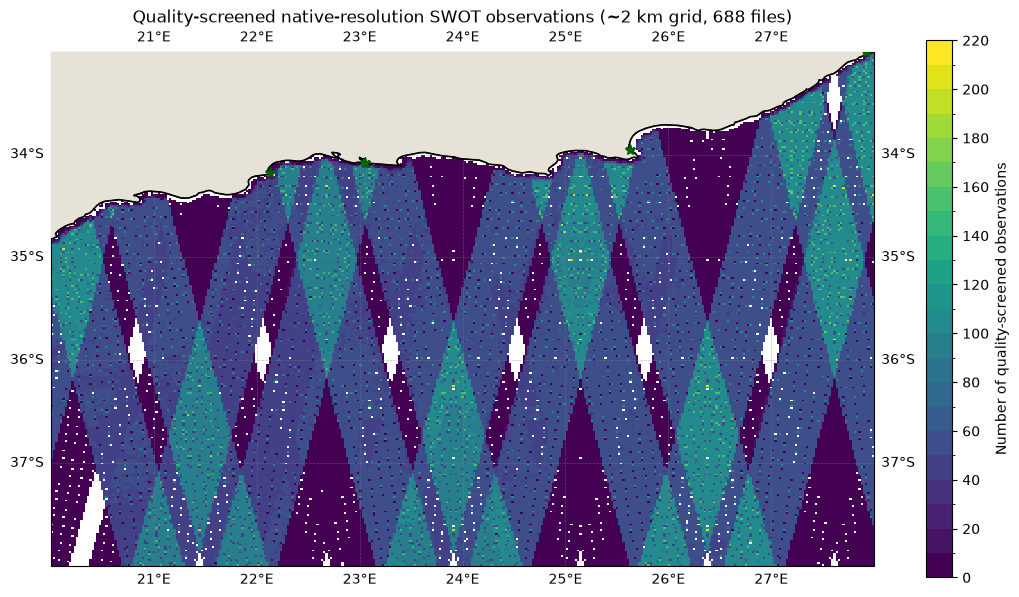

Total SWOT L3 Expert candidate files: 688
Native grid shape: 278 lat x 363 lon (~2 km resolution)
Total quality-screened SWOT pixel observations in domain: 3,958,513
Maximum observations in a single grid cell: 214
Grid cells with at least 1 quality-screened observation: 78,110


In [19]:
# Map spatial distribution of quality-screened native-resolution SWOT observation counts.
from concurrent.futures import ThreadPoolExecutor
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Build a ~2 km native-resolution grid over the same domain used for the HF-radar figures.
SWOT_NATIVE_RESOLUTION_KM = 2.0
SWOT_COUNT_BBOX = plot_bounds_extended
VALID_SWOT_QUALITY_FLAGS = (0,)
domain_mid_latitude = (SWOT_COUNT_BBOX[2] + SWOT_COUNT_BBOX[3]) / 2
km_per_degree_lat = 111.32
km_per_degree_lon = 111.32 * np.cos(np.deg2rad(domain_mid_latitude))
n_swot_lat = max(int(round((SWOT_COUNT_BBOX[3] - SWOT_COUNT_BBOX[2]) * km_per_degree_lat / SWOT_NATIVE_RESOLUTION_KM)), 1)
n_swot_lon = max(int(round((SWOT_COUNT_BBOX[1] - SWOT_COUNT_BBOX[0]) * km_per_degree_lon / SWOT_NATIVE_RESOLUTION_KM)), 1)

swot_lat_edges = np.linspace(SWOT_COUNT_BBOX[2], SWOT_COUNT_BBOX[3], n_swot_lat + 1)
swot_lon_edges = np.linspace(SWOT_COUNT_BBOX[0], SWOT_COUNT_BBOX[1], n_swot_lon + 1)
swot_grid_shape = (n_swot_lat, n_swot_lon)

swot_l3_all_files = sorted(SWOT_L3_DIR.glob('SWOT_L3_LR_SSH_Expert_*.nc'))
if not swot_l3_all_files:
    raise FileNotFoundError(f'No SWOT L3 Expert files found under {SWOT_L3_DIR}')


def accumulate_swot_chunk(file_paths):
    count_chunk = np.zeros(swot_grid_shape, dtype=np.int64)
    for path in file_paths:
        try:
            with xr.open_dataset(path) as dataset:
                required = {'ugos_filtered', 'vgos_filtered', 'longitude', 'latitude', 'quality_flag'}
                if not required.issubset(dataset.variables):
                    continue
                longitude = dataset['longitude'].values
                latitude = dataset['latitude'].values
                valid = (
                    np.isfinite(dataset['ugos_filtered'].values)
                    & np.isfinite(dataset['vgos_filtered'].values)
                    & np.isin(dataset['quality_flag'].values, VALID_SWOT_QUALITY_FLAGS)
                    & (longitude >= SWOT_COUNT_BBOX[0]) & (longitude <= SWOT_COUNT_BBOX[1])
                    & (latitude >= SWOT_COUNT_BBOX[2]) & (latitude <= SWOT_COUNT_BBOX[3])
                )
        except Exception:
            continue
        if not valid.any():
            continue
        pixel_hist, _, _ = np.histogram2d(
            latitude[valid], longitude[valid],
            bins=(swot_lat_edges, swot_lon_edges),
        )
        count_chunk += pixel_hist.astype(np.int64)
    return count_chunk


num_swot_workers = 16
swot_chunk_size = int(np.ceil(len(swot_l3_all_files) / num_swot_workers))
swot_file_chunks = [
    swot_l3_all_files[i:i + swot_chunk_size]
    for i in range(0, len(swot_l3_all_files), swot_chunk_size)
]

with ThreadPoolExecutor(max_workers=num_swot_workers) as executor:
    swot_results = list(executor.map(accumulate_swot_chunk, swot_file_chunks))

swot_obs_count_native = sum(swot_results)

# Plot observation count map on the native ~2 km grid.
swot_count_display = np.where(swot_obs_count_native > 0, swot_obs_count_native, np.nan)

# Discrete colour levels from 0 to 220 in steps of 10.
swot_count_levels = np.arange(0, 230, 10)
swot_count_cmap = plt.get_cmap('viridis', len(swot_count_levels) - 1)
swot_count_norm = mcolors.BoundaryNorm(swot_count_levels, swot_count_cmap.N)

figure, axis = plt.subplots(figsize=(11, 6), subplot_kw={'projection': ccrs.PlateCarree()})
axis.set_extent(SWOT_COUNT_BBOX, crs=ccrs.PlateCarree())
axis.add_feature(cfeature.LAND, facecolor='#e7e2d8', edgecolor='black', linewidth=0.8, zorder=4)
axis.coastlines(resolution='10m', color='black', linewidth=1.2, zorder=5)

mesh = axis.pcolormesh(
    swot_lon_edges,
    swot_lat_edges,
    swot_count_display,
    cmap=swot_count_cmap,
    norm=swot_count_norm,
    shading='flat',
    transform=ccrs.PlateCarree(),
    zorder=1,
)
figure.colorbar(mesh, ax=axis, ticks=swot_count_levels[::2], label='Number of quality-screened observations')

for name, (target_lon, target_lat) in TARGET_POINTS.items():
    axis.plot(target_lon, target_lat, marker='*', color='darkgreen', markersize=8, transform=ccrs.PlateCarree(), zorder=6)

axis.set_title(f'Quality-screened native-resolution SWOT observations (~{SWOT_NATIVE_RESOLUTION_KM:.0f} km grid, {len(swot_l3_all_files):,} files)')
axis.set_xlabel('Longitude (degrees east)')
axis.set_ylabel('Latitude (degrees south)')
axis.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
figure.tight_layout()
plt.show()

print(f'Total SWOT L3 Expert candidate files: {len(swot_l3_all_files):,}')
print(f'Native grid shape: {n_swot_lat} lat x {n_swot_lon} lon (~{SWOT_NATIVE_RESOLUTION_KM:.0f} km resolution)')
print(f'Total quality-screened SWOT pixel observations in domain: {int(swot_obs_count_native.sum()):,}')
print(f'Maximum observations in a single grid cell: {int(swot_obs_count_native.max()):,}')
print(f'Grid cells with at least 1 quality-screened observation: {(swot_obs_count_native > 0).sum():,}')

In [15]:
# Download the Copernicus Marine multi-observation surface-current dataset for the SWOT domain and period
import importlib.util
import subprocess
import sys

PRODUCT_ID = 'MULTIOBS_GLO_PHY_MYNRT_015_003'
DATASET_ID = 'cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i'
COPERNICUS_DOWNLOAD_DIR = DOWNLOAD_DIR / 'copernicusmarine' / DATASET_ID
COPERNICUS_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

if importlib.util.find_spec('copernicusmarine') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'copernicusmarine'])

import copernicusmarine

print(f'Product page: https://data.marine.copernicus.eu/product/{PRODUCT_ID}/description')
print(f'Dataset ID: {DATASET_ID}')
print(f'Dataset WMS capabilities: https://wmts.marine.copernicus.eu/teroWmts/{PRODUCT_ID}/{DATASET_ID}?request=GetCapabilities&service=WMS')
print(f'Download directory: {COPERNICUS_DOWNLOAD_DIR}')
print(f'Spatial subset: {SWOT_COUNT_BBOX}')
print(f'Time subset: {SWOT_START_DATE.date()} to {SWOT_END_DATE.date()}')

# Total velocity, Ekman velocity, and tidal velocity components.
COPERNICUS_CURRENT_VARIABLES = ['uo', 'vo', 'ue', 've', 'utide', 'vtide']
print(f'Requested current variables: {COPERNICUS_CURRENT_VARIABLES}')

copernicusmarine.subset(
    dataset_id=DATASET_ID,
    variables=COPERNICUS_CURRENT_VARIABLES,
    minimum_longitude=SWOT_COUNT_BBOX[0],
    maximum_longitude=SWOT_COUNT_BBOX[1],
    minimum_latitude=SWOT_COUNT_BBOX[2],
    maximum_latitude=SWOT_COUNT_BBOX[3],
    start_datetime=SWOT_START_DATE.strftime('%Y-%m-%dT%H:%M:%S'),
    end_datetime=SWOT_END_DATE.strftime('%Y-%m-%dT%H:%M:%S'),
    output_directory=str(COPERNICUS_DOWNLOAD_DIR),
    force_download=False,
)
print(f'Spatial-temporal subset download complete: {COPERNICUS_DOWNLOAD_DIR}')

WARNING - 2026-09-18T09:49:01Z - 'force_download' has been deprecated.


Product page: https://data.marine.copernicus.eu/product/MULTIOBS_GLO_PHY_MYNRT_015_003/description
Dataset ID: cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i
Dataset WMS capabilities: https://wmts.marine.copernicus.eu/teroWmts/MULTIOBS_GLO_PHY_MYNRT_015_003/cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i?request=GetCapabilities&service=WMS
Download directory: <repo>/data/raw/copernicusmarine/cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i
Spatial subset: (20.0, 28.0, -38.0, -33.0)
Time subset: 2023-07-26 to 2026-09-11
Requested current variables: ['uo', 'vo', 'ue', 've', 'utide', 'vtide']


INFO - 2026-09-18T09:49:02Z - Selected dataset version: "202411"
INFO - 2026-09-18T09:49:02Z - Selected dataset part: "default"


  0%|          | [00:00<?]

INFO - 2026-09-18T09:49:29Z - Total size of the download: 402.08 MB.


Spatial-temporal subset download complete: <repo>/data/raw/copernicusmarine/cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i


In [16]:
# Load the downloaded Copernicus Marine subset and print available variables
import xarray as xr

COPERNICUS_FILES = sorted(COPERNICUS_DOWNLOAD_DIR.rglob('*.nc'))
if not COPERNICUS_FILES:
    raise FileNotFoundError(f'No NetCDF files found under {COPERNICUS_DOWNLOAD_DIR}. Run the download cell first.')

COPERNICUS_DATASET = xr.open_dataset(COPERNICUS_FILES[0])
print(f'Loaded file: {COPERNICUS_FILES[0]}')
print(f'Dimensions: {dict(COPERNICUS_DATASET.sizes)}')
print(f'Coordinates: {list(COPERNICUS_DATASET.coords)}')
print('Available variables:')
for variable_name, variable in COPERNICUS_DATASET.data_vars.items():
    print(f"  {variable_name}: dimensions={variable.dims}, shape={variable.shape}, units={variable.attrs.get('units', 'unknown')}")
print(f'Global attributes: {dict(COPERNICUS_DATASET.attrs)}')

Loaded file: <repo>/data/raw/copernicusmarine/cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i/cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i_multi-vars_20.12E-27.88E_37.88S-33.12S_0.00-15.00m_2023-07-26-2026-09-11.nc
Dimensions: {'time': 27433, 'depth': 2, 'latitude': 20, 'longitude': 32}
Coordinates: ['depth', 'latitude', 'longitude', 'time']
Available variables:
  uo: dimensions=('time', 'depth', 'latitude', 'longitude'), shape=(27433, 2, 20, 32), units=m/s
  vo: dimensions=('time', 'depth', 'latitude', 'longitude'), shape=(27433, 2, 20, 32), units=m/s
  ue: dimensions=('time', 'depth', 'latitude', 'longitude'), shape=(27433, 2, 20, 32), units=m/s
  ve: dimensions=('time', 'depth', 'latitude', 'longitude'), shape=(27433, 2, 20, 32), units=m/s
  utide: dimensions=('time', 'latitude', 'longitude'), shape=(27433, 20, 32), units=m/s
  vtide: dimensions=('time', 'latitude', 'longitude'), shape=(27433, 20, 32), units=m/s
Global attributes: {'Conventions': 'CF-1.6', 'contact': 'servicedesk.cmems

In [17]:
# Download Copernicus Marine surface Stokes-drift velocity components for the SWOT domain and period
import importlib.util
import subprocess
import sys

WAVE_PRODUCT_ID = 'GLOBAL_ANALYSISFORECAST_WAV_001_027'
WAVE_DATASET_ID = 'cmems_mod_glo_wav_anfc_0.083deg_PT3H-i'
WAVE_VARIABLES = ['VSDX', 'VSDY']
WAVE_DOWNLOAD_DIR = DOWNLOAD_DIR / 'copernicusmarine' / WAVE_DATASET_ID
WAVE_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

if importlib.util.find_spec('copernicusmarine') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'copernicusmarine'])

import copernicusmarine

print(f'Product page: https://data.marine.copernicus.eu/product/{WAVE_PRODUCT_ID}/description')
print(f'Dataset ID: {WAVE_DATASET_ID}')
print(f'Dataset WMS capabilities: https://wmts.marine.copernicus.eu/teroWmts/{WAVE_PRODUCT_ID}/{WAVE_DATASET_ID}?request=GetCapabilities&service=WMS')
print(f'Download directory: {WAVE_DOWNLOAD_DIR}')
print(f'Spatial subset: {SWOT_COUNT_BBOX}')
print(f'Time subset: {SWOT_START_DATE.date()} to {SWOT_END_DATE.date()}')
print(f'Requested variables: {WAVE_VARIABLES}')

copernicusmarine.subset(
    dataset_id=WAVE_DATASET_ID,
    variables=WAVE_VARIABLES,
    minimum_longitude=SWOT_COUNT_BBOX[0],
    maximum_longitude=SWOT_COUNT_BBOX[1],
    minimum_latitude=SWOT_COUNT_BBOX[2],
    maximum_latitude=SWOT_COUNT_BBOX[3],
    start_datetime=SWOT_START_DATE.strftime('%Y-%m-%dT%H:%M:%S'),
    end_datetime=SWOT_END_DATE.strftime('%Y-%m-%dT%H:%M:%S'),
    output_directory=str(WAVE_DOWNLOAD_DIR),
    force_download=False,
)
print(f'Surface Stokes-drift subset download complete: {WAVE_DOWNLOAD_DIR}')

WARNING - 2026-09-18T09:49:29Z - 'force_download' has been deprecated.


Product page: https://data.marine.copernicus.eu/product/GLOBAL_ANALYSISFORECAST_WAV_001_027/description
Dataset ID: cmems_mod_glo_wav_anfc_0.083deg_PT3H-i
Dataset WMS capabilities: https://wmts.marine.copernicus.eu/teroWmts/GLOBAL_ANALYSISFORECAST_WAV_001_027/cmems_mod_glo_wav_anfc_0.083deg_PT3H-i?request=GetCapabilities&service=WMS
Download directory: <repo>/data/raw/copernicusmarine/cmems_mod_glo_wav_anfc_0.083deg_PT3H-i
Spatial subset: (20.0, 28.0, -38.0, -33.0)
Time subset: 2023-07-26 to 2026-09-11
Requested variables: ['VSDX', 'VSDY']


INFO - 2026-09-18T09:49:30Z - Selected dataset version: "202411"
INFO - 2026-09-18T09:49:30Z - Selected dataset part: "default"


  0%|          | [00:00<?]

INFO - 2026-09-18T09:49:39Z - Total size of the download: 206.54 MB.


Surface Stokes-drift subset download complete: <repo>/data/raw/copernicusmarine/cmems_mod_glo_wav_anfc_0.083deg_PT3H-i


In [18]:
# Confirm the downloaded Stokes-drift variables and their metadata
import xarray as xr

WAVE_FILES = sorted(WAVE_DOWNLOAD_DIR.rglob('*.nc'))
if not WAVE_FILES:
    raise FileNotFoundError(f'No wave NetCDF files found under {WAVE_DOWNLOAD_DIR}. Run the download cell first.')

WAVE_DATASET = xr.open_dataset(WAVE_FILES[0])
print(f'Loaded file: {WAVE_FILES[0]}')
print(f'Dimensions: {dict(WAVE_DATASET.sizes)}')
print(f'Coordinates: {list(WAVE_DATASET.coords)}')

for variable_name in WAVE_VARIABLES:
    if variable_name not in WAVE_DATASET:
        raise KeyError(f'Requested Stokes-drift variable not found: {variable_name}')
    variable = WAVE_DATASET[variable_name]
    print(f'{variable_name}:')
    print(f'  dimensions: {variable.dims}')
    print(f'  shape: {variable.shape}')
    print(f'  units: {variable.attrs.get("units", "unknown")}')
    print(f'  standard name: {variable.attrs.get("standard_name", "unknown")}')
    print(f'  long name: {variable.attrs.get("long_name", "unknown")}')
    print(f'  surface field: {"depth" not in variable.dims}')

print(f'Confirmed Stokes-drift variables: {WAVE_VARIABLES}')

Loaded file: <repo>/data/raw/copernicusmarine/cmems_mod_glo_wav_anfc_0.083deg_PT3H-i/cmems_mod_glo_wav_anfc_0.083deg_PT3H-i_VSDX-VSDY_20.00E-28.00E_38.00S-33.00S_2023-07-26-2026-09-11.nc
Dimensions: {'time': 9145, 'latitude': 61, 'longitude': 97}
Coordinates: ['latitude', 'longitude', 'time']
VSDX:
  dimensions: ('time', 'latitude', 'longitude')
  shape: (9145, 61, 97)
  units: m s-1
  standard name: sea_surface_wave_stokes_drift_x_velocity
  long name: Stokes drift U
  surface field: True
VSDY:
  dimensions: ('time', 'latitude', 'longitude')
  shape: (9145, 61, 97)
  units: m s-1
  standard name: sea_surface_wave_stokes_drift_y_velocity
  long name: Stokes drift V
  surface field: True
Confirmed Stokes-drift variables: ['VSDX', 'VSDY']
